# Pattern Recognition & Machine Learning: Risk Factor Prediction of Chronic Kidney Disease
### Low-Level Deep Neural Network & Logistic Modeling in PyTorch

**Dataset:** UCI Machine Learning Repository — [Dataset 857: Risk Factor Prediction of Chronic Kidney Disease](https://archive.ics.uci.edu/dataset/857/risk+factor+prediction+of+chronic+kidney+disease)  
**Study Reference:** Islam et al. (2020), *Risk Factor Prediction of Chronic Kidney Disease based on Machine Learning Algorithms*  
**Environment:** Python 3.11 with Pipenv, Pure PyTorch Low-Level Tensor Engine  

---

### Abstract & Problem Formulation
Chronic Kidney Disease (CKD) is characterized by gradual loss of renal function over months or years. Early detection is crucial because early therapeutic intervention can prevent or delay progression to End-Stage Renal Disease (ESRD).

In this study, we build a **low-level PyTorch neural network architecture** to classify and evaluate risk factors associated with CKD using 26 clinical, biochemical, and demographic parameters. Rather than relying on high-level automated black-box libraries, this implementation formulates the entire deep learning workflow—from interval normalization and tensor batching to gradient backpropagation and feature attribution—using low-level PyTorch operations.

$$\mathcal{L}_{BCE}(\mathbf{y}, \mathbf{\hat{y}}) = -\frac{1}{N}\sum_{i=1}^N \left[ y_i \log(\sigma(z_i)) + (1 - y_i) \log(1 - \sigma(z_i)) \right]$$


## 1. Environment Configuration & Low-Level Imports
We verify our PyTorch compute environment, configure reproducible seeds, and load essential mathematical utilities.


In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath(".."))

import math
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F

# Set styling and reproducibility
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available : {torch.cuda.is_available()}")


PyTorch Version: 2.14.0+cpu
CUDA Available : False


## 2. Dataset Ingestion & Exploratory Data Analysis (EDA)
The UCI CKD dataset contains real patient records from Enam Medical College, Savar, Dhaka, Bangladesh.
The features are structured across 29 columns with clinical interval discretizations. We parse the raw strings, extract median values, and analyze target class distributions.


In [2]:
df_raw = pd.read_csv('../data/ckd-dataset-v2.csv', encoding='utf-8')
print(f"Raw Dataset Dimensions: {df_raw.shape}")

metadata_type = df_raw.iloc[0]
metadata_role = df_raw.iloc[1]
df_data = df_raw.iloc[2:].reset_index(drop=True)

print(f"Clean Patient Records: {len(df_data)} patients")
dist_pct = df_data['affected'].value_counts(normalize=True).mul(100).round(2).to_dict()
print(f"Target Distribution (affected): {dist_pct}")
df_data.head(5)


Raw Dataset Dimensions: (202, 29)
Clean Patient Records: 200 patients
Target Distribution (affected): {'1': 64.0, '0': 36.0}


,bp (Diastolic),bp limit,sg,al,class,rbc,su,pc,pcc,ba,...,htn,dm,cad,appet,pe,ane,grf,stage,affected,age
0,0,0,1.019 - 1.021,1 - 1,ckd,0,< 0,0,0,0,...,0,0,0,0,0,0,≥ 227.944,s1,1,< 12
1,0,0,1.009 - 1.011,< 0,ckd,0,< 0,0,0,0,...,0,0,0,0,0,0,≥ 227.944,s1,1,< 12
2,0,0,1.009 - 1.011,≥ 4,ckd,1,< 0,1,0,1,...,0,0,0,1,0,0,127.281 - 152.446,s1,1,< 12
3,1,1,1.009 - 1.011,3 - 3,ckd,0,< 0,0,0,0,...,0,0,0,0,0,0,127.281 - 152.446,s1,1,< 12
4,0,0,1.015 - 1.017,< 0,ckd,0,< 0,0,0,0,...,0,1,0,1,1,0,127.281 - 152.446,s1,1,12 - 20


## 3. Clinical Interval Parsing & Tensor Preprocessing
We define mathematical parsing for clinical range strings (e.g. `< 112` $\to 84$, `112 - 154` $\to 133$, `≥ 448` $\to 515.2$) and impute missing values using robust median statistics before performing Z-score standardization:

$$z = \frac{x - \mu}{\sigma}$$


In [3]:
from src.preprocess import FEATURE_COLUMNS, FEATURE_LABELS, parse_interval_to_numeric, load_and_preprocess_data, get_train_val_test_split

X_num, X_scaled, y, preprocessor_meta = load_and_preprocess_data('../data/ckd-dataset-v2.csv')

print(f"Feature Matrix Shape: {X_scaled.shape}")
print(f"Total Features Extracted: {len(FEATURE_COLUMNS)}")

key_biomarkers = ['sc', 'bgr', 'bu', 'hemo', 'grf', 'al', 'bp (Diastolic)', 'age']
X_num[key_biomarkers].describe().T


Feature Matrix Shape: (200, 26)
Total Features Extracted: 26


,count,mean,std,min,25%,50%,75%,max
sc,200.0,3.906950,3.311136,2.737500,2.737500,2.73750,2.7375,33.1775
bgr,200.0,148.673000,84.466042,84.000000,84.000000,133.00000,175.0000,515.2000
bu,200.0,66.921925,51.305863,36.075000,36.075000,36.07500,67.1500,405.8350
hemo,200.0,12.361875,3.113791,4.575000,10.650000,11.95000,14.5500,18.9750
grf,200.0,68.233723,56.342761,19.963125,19.963125,39.20035,89.5320,262.1356
al,200.0,1.019000,1.423789,0.000000,0.000000,0.00000,2.0000,4.6000
bp (Diastolic),200.0,0.540000,0.499648,0.000000,0.000000,1.00000,1.0000,1.0000
age,200.0,53.700000,16.874142,9.000000,47.000000,55.00000,62.5000,85.1000


## 4. Biomarker Visualizations & Correlation Analysis
We visualize the relationship between key clinical renal markers (Serum Creatinine, Blood Glucose, Hemoglobin, eGFR) and chronic kidney disease diagnosis.


D:\Temp\ipykernel_16020\1166344714.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=y, y=X_num['sc'], ax=axes[0, 0], palette=['#2ecc71', '#e74c3c'])
D:\Temp\ipykernel_16020\1166344714.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(['Healthy (0)', 'CKD Affected (1)'])


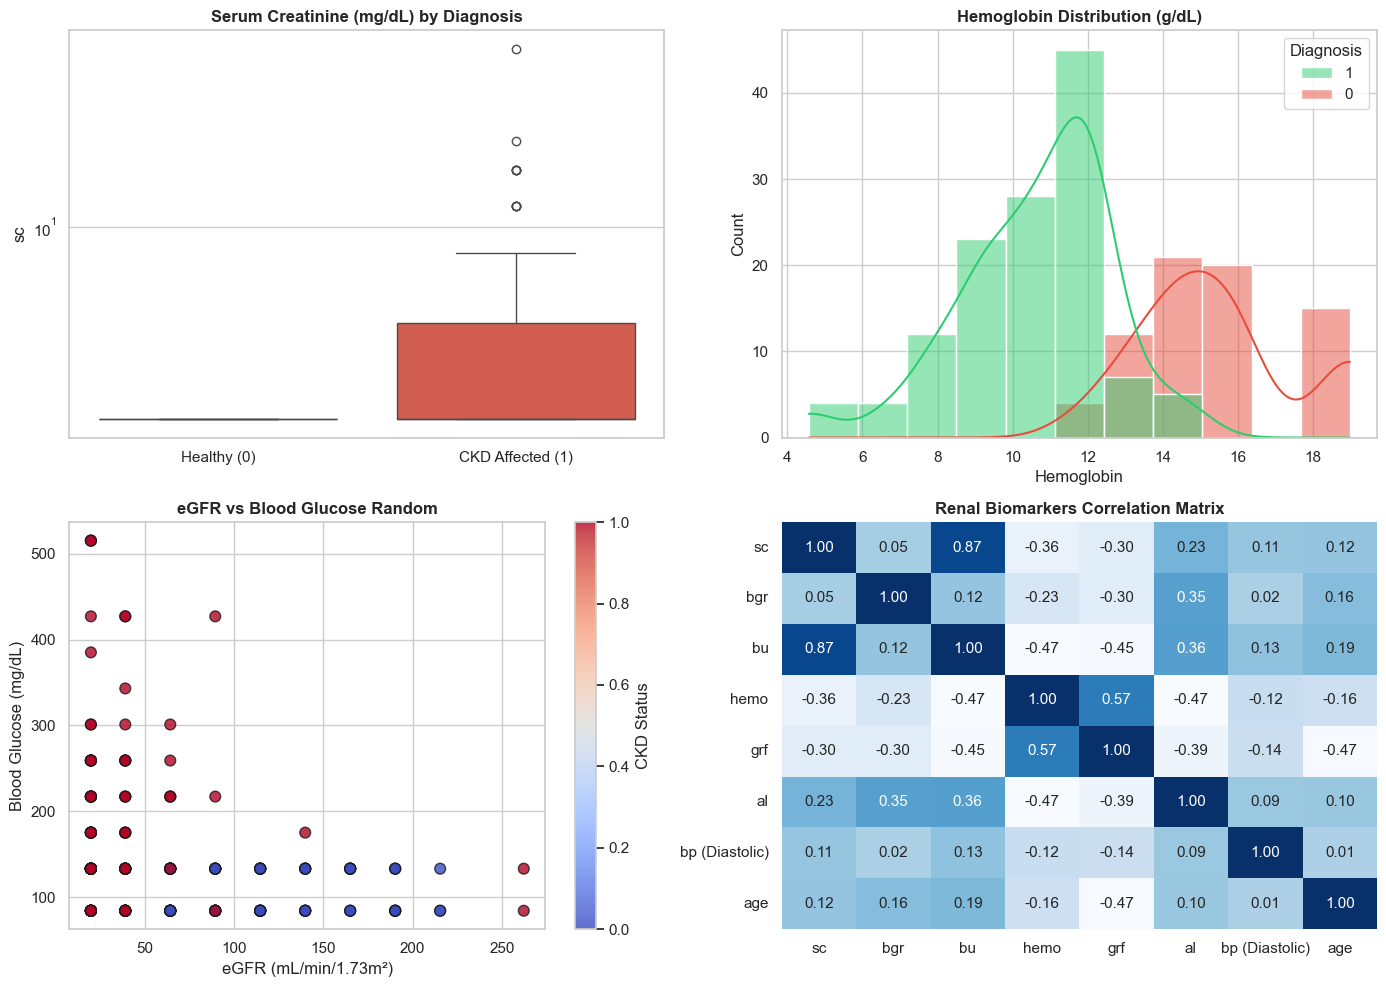

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Serum Creatinine vs CKD
sns.boxplot(x=y, y=X_num['sc'], ax=axes[0, 0], palette=['#2ecc71', '#e74c3c'])
axes[0, 0].set_title("Serum Creatinine (mg/dL) by Diagnosis", fontweight='bold')
axes[0, 0].set_xticklabels(['Healthy (0)', 'CKD Affected (1)'])
axes[0, 0].set_yscale('log')

# 2. Hemoglobin vs CKD
df_hemo = pd.DataFrame({'Hemoglobin': X_num['hemo'], 'Diagnosis': y.astype(str)})
sns.histplot(data=df_hemo, x='Hemoglobin', hue='Diagnosis', kde=True, ax=axes[0, 1], palette=['#2ecc71', '#e74c3c'])
axes[0, 1].set_title("Hemoglobin Distribution (g/dL)", fontweight='bold')

# 3. eGFR vs Blood Glucose
scatter = axes[1, 0].scatter(X_num['grf'], X_num['bgr'], c=y, cmap='coolwarm', alpha=0.8, edgecolors='k', s=60)
axes[1, 0].set_title("eGFR vs Blood Glucose Random", fontweight='bold')
axes[1, 0].set_xlabel("eGFR (mL/min/1.73m²)")
axes[1, 0].set_ylabel("Blood Glucose (mg/dL)")
plt.colorbar(scatter, ax=axes[1, 0], label="CKD Status")

# 4. Correlation Matrix of Key Features
corr = X_num[key_biomarkers].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", ax=axes[1, 1], cbar=False)
axes[1, 1].set_title("Renal Biomarkers Correlation Matrix", fontweight='bold')

plt.tight_layout()
plt.show()


## 5. Low-Level PyTorch Neural Network Architecture
We construct **CKDRiskNet**, a deep Multi-Layer Perceptron (MLP) with Batch Normalization, Dropout regularization, and Kaiming parameter initialization.

### Layer Mathematical Formulation:
$$\mathbf{h}^{(1)} = \text{ReLU}\left( \text{BN}(\mathbf{W}^{(1)} \mathbf{x} + \mathbf{b}^{(1)}) \right)$$
$$\mathbf{h}^{(2)} = \text{ReLU}\left( \text{BN}(\mathbf{W}^{(2)} \mathbf{h}^{(1)} + \mathbf{b}^{(2)}) \right)$$
$$\mathbf{h}^{(3)} = \text{ReLU}\left( \mathbf{W}^{(3)} \mathbf{h}^{(2)} + \mathbf{b}^{(3)} \right)$$
$$z = \mathbf{W}^{(out)} \mathbf{h}^{(3)} + b^{(out)}$$
$$\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}$$


In [5]:
from src.model import CKDRiskNet, LowLevelLogisticRegression

(X_train, y_train), (X_val, y_val), (X_test, y_test) = get_train_val_test_split(X_scaled, y, seed=42)

print(f"Training Samples  : {X_train.shape[0]}")
print(f"Validation Samples: {X_val.shape[0]}")
print(f"Test Samples      : {X_test.shape[0]}")

model = CKDRiskNet(input_dim=X_train.shape[1], hidden1=32, hidden2=16, hidden3=8, dropout_rate=0.2)
print("Model Architecture Summary:")
print(model)


Training Samples  : 140
Validation Samples: 30
Test Samples      : 30
Model Architecture Summary:
CKDRiskNet(
  (fc1): Linear(in_features=26, out_features=32, bias=True)
  (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc2): Linear(in_features=32, out_features=16, bias=True)
  (bn2): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc3): Linear(in_features=16, out_features=8, bias=True)
  (fc_out): Linear(in_features=8, out_features=1, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)


## 6. Low-Level Training Loop with Early Stopping
We implement explicit mini-batch gradient descent with dynamic loss tracking, validation evaluation, and early stopping to prevent overfitting on clinical data.


In [6]:
from src.train import train_model, compute_metrics, export_model_for_js

trained_model, history = train_model(
    model=model,
    train_data=(X_train, y_train),
    val_data=(X_val, y_val),
    epochs=150,
    lr=0.008,
    weight_decay=1e-4,
    batch_size=32
)


Epoch 001 | Train Loss: 0.6523 | Val Loss: 0.4609 | Val Acc: 90.00%


Epoch 020 | Train Loss: 0.0487 | Val Loss: 0.0456 | Val Acc: 100.00%


Epoch 040 | Train Loss: 0.0445 | Val Loss: 0.1076 | Val Acc: 96.67%


Early stopping at epoch 60. Best Val Loss: 0.0199


## 7. Model Convergence & Learning Curves
We plot the training and validation loss along with classification accuracy curves across epochs.


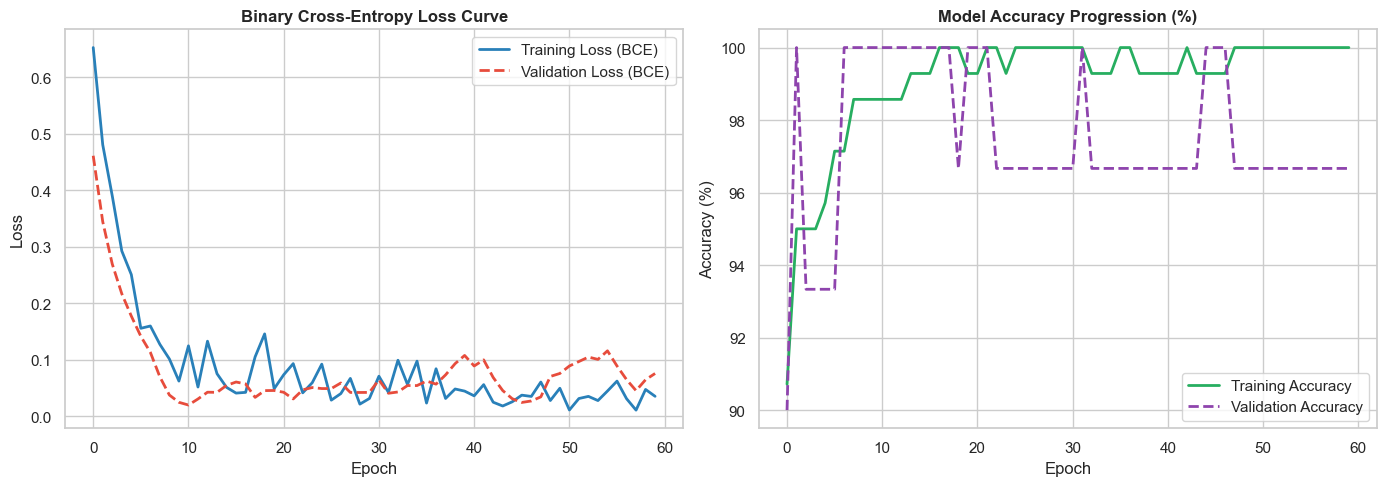

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss Curves
axes[0].plot(history['train_loss'], label='Training Loss (BCE)', color='#2980b9', lw=2)
axes[0].plot(history['val_loss'], label='Validation Loss (BCE)', color='#e74c3c', lw=2, linestyle='--')
axes[0].set_title("Binary Cross-Entropy Loss Curve", fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Accuracy Curves
axes[1].plot([acc * 100 for acc in history['train_acc']], label='Training Accuracy', color='#27ae60', lw=2)
axes[1].plot([acc * 100 for acc in history['val_acc']], label='Validation Accuracy', color='#8e44ad', lw=2, linestyle='--')
axes[1].set_title("Model Accuracy Progression (%)", fontweight='bold')
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()

plt.tight_layout()
plt.show()


## 8. Test Set Evaluation & Diagnostic Metrics
We rigorously evaluate the trained PyTorch network on unseen test data using Classification Metrics (Accuracy, Precision, Recall, F1-Score, ROC-AUC) and Confusion Matrix.


       TEST SET DIAGNOSTIC PERFORMANCE       
  Classification Accuracy : 93.33%
  Precision (Sensitivity) : 100.00%
  Recall (Specificity)    : 90.00%
  F1-Score                : 0.9474
  Area Under ROC (AUC)    : 1.0000


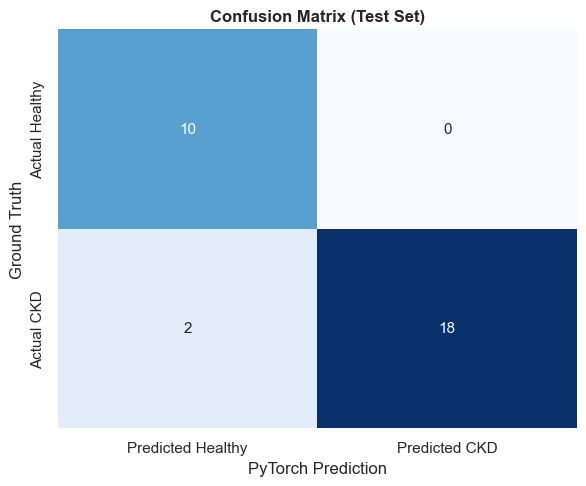

In [8]:
test_probs = trained_model.predict_proba(X_test)
test_metrics = compute_metrics(y_test, test_probs)

print("=" * 45)
print("       TEST SET DIAGNOSTIC PERFORMANCE       ")
print("=" * 45)
print(f"  Classification Accuracy : {test_metrics['accuracy']*100:.2f}%")
print(f"  Precision (Sensitivity) : {test_metrics['precision']*100:.2f}%")
print(f"  Recall (Specificity)    : {test_metrics['recall']*100:.2f}%")
print(f"  F1-Score                : {test_metrics['f1']:.4f}")
print(f"  Area Under ROC (AUC)    : {test_metrics['roc_auc']:.4f}")
print("=" * 45)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
cm = np.array(test_metrics['confusion_matrix'])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted Healthy', 'Predicted CKD'],
            yticklabels=['Actual Healthy', 'Actual CKD'])
plt.title("Confusion Matrix (Test Set)", fontweight='bold')
plt.ylabel("Ground Truth")
plt.xlabel("PyTorch Prediction")
plt.tight_layout()
plt.show()


## 9. Feature Importance & Risk Factor Attribution
To ensure clinical interpretability, we compute feature saliency via input gradient attribution:

$$\text{Attribution}_j = \left| \frac{\partial z}{\partial x_j} \cdot x_j \right|$$


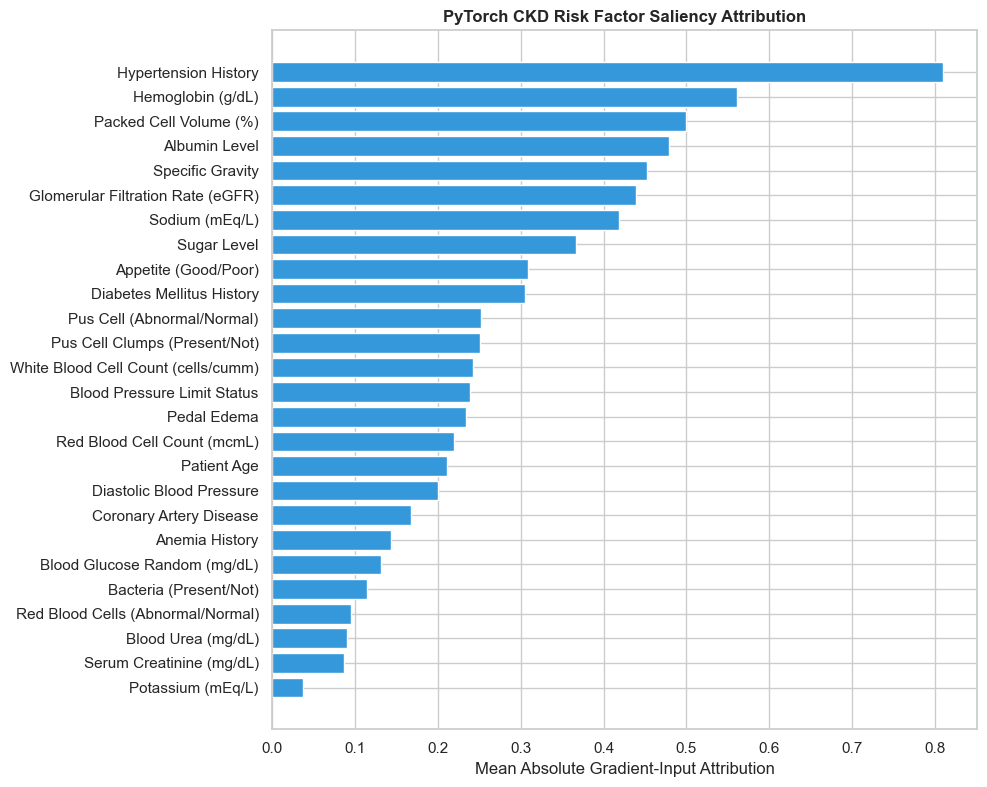

In [9]:
model.eval()
X_test_grad = X_test.clone().detach().requires_grad_(True)
logits = model(X_test_grad)
logits.sum().backward()

attributions = torch.abs(X_test_grad.grad * X_test_grad).mean(dim=0).detach().cpu().numpy()
feature_names = [FEATURE_LABELS.get(col, col) for col in FEATURE_COLUMNS]

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': attributions
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(df_importance['Feature'], df_importance['Importance'], color='#3498db')
plt.title("PyTorch CKD Risk Factor Saliency Attribution", fontweight='bold')
plt.xlabel("Mean Absolute Gradient-Input Attribution")
plt.tight_layout()
plt.show()


## 10. Model Artifact Serialization for JavaScript Runtime
We export the model parameters and preprocessor metadata to JSON. This allows our standalone JavaScript application to run real-time in-browser neural network inference with zero backend overhead.


In [10]:
export_model_for_js(trained_model, preprocessor_meta, export_dir="../model")

with open("../model/model_weights.json", "r") as f:
    weights = json.load(f)
print(f"Exported Model Type: {weights['type']}")
print(f"Exported Weight Keys: {list(weights.keys())}")


Model and Preprocessor exported successfully to ../model and web/assets/
Exported Model Type: CKDRiskNet
Exported Weight Keys: ['type', 'fc1_w', 'fc1_b', 'bn1_mean', 'bn1_var', 'bn1_w', 'bn1_b', 'fc2_w', 'fc2_b', 'bn2_mean', 'bn2_var', 'bn2_w', 'bn2_b', 'fc3_w', 'fc3_b', 'fc_out_w', 'fc_out_b']
